In [289]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import numpy as np 
from scipy.stats import chi2_contingency, kruskal
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report



#### Loading the dataset 


In [240]:
financial_health = pd.read_csv(r"C:\Users\USER\Downloads\LuqDevHq\Financial_health\Data\financial_health.csv")

In [241]:
financial_health.head()

,ID,country,owner_age,attitude_stable_business_environment,attitude_worried_shutdown,compliance_income_tax,perception_insurance_doesnt_cover_losses,perception_cannot_afford_insurance,personal_income,business_expenses,...,has_internet_banking,has_debit_card,future_risk_theft_stock,business_age_months,medical_insurance,funeral_insurance,motivation_make_more_money,uses_friends_family_savings,uses_informal_lender,Target
0,ID_3CFL0U,eswatini,63.0,Yes,No,No,No,Yes,3000.0,6000.0,...,Never had,Never had,NaN,6.0,Never had,Used to have but don’t have now,NaN,Never had,Never had,Low
1,ID_XWI7G3,zimbabwe,39.0,No,Yes,Yes,No,Yes,NaN,NaN,...,NaN,NaN,No,3.0,Never had,Never had,NaN,NaN,NaN,Medium
2,ID_TY93LV,malawi,34.0,Don’t know or N/A,No,No,Don't know,Yes,30000.0,6000.0,...,Never had,Never had,Yes,NaN,NaN,NaN,Yes,NaN,NaN,Low
3,ID_9OP2C8,malawi,28.0,Yes,No,No,No,No,180000.0,60000.0,...,Never had,Never had,No,NaN,NaN,NaN,Yes,Never had,Have now,Low
4,ID_13REYS,zimbabwe,43.0,Yes,No,No,Yes,Yes,50.0,2400.0,...,NaN,NaN,No,0.0,Never had,Never had,Yes,NaN,NaN,Low


#### Summary of the data

In [242]:
def basic_checks(financial_health):
    print("-"*35, "Duplicates","-"*35)
    print(financial_health.duplicated().sum())
    print("-"*35, "Shape", "-"*35)
    print(financial_health.shape)
    print("-"*35, "Missing Values", "-"*35)
    print(financial_health.isna().sum())
    print("-"*35, "Data Types", "-"*35)
    print(financial_health.dtypes)
    print("-"*35, "Summary Statistics (Numerical)", "-"*35)
    print(display(financial_health.describe().T))
    print("-"*35, "Summary Statistics Categorical Data", "-"*35)
    print(display(financial_health.describe(include = ["str","object"]).T))

In [243]:
basic_checks(financial_health)

----------------------------------- Duplicates -----------------------------------
0
----------------------------------- Shape -----------------------------------
(9618, 39)
----------------------------------- Missing Values -----------------------------------
ID                                                                     0
country                                                                0
owner_age                                                              0
attitude_stable_business_environment                                   2
attitude_worried_shutdown                                              2
compliance_income_tax                                                  4
perception_insurance_doesnt_cover_losses                               5
perception_cannot_afford_insurance                                     5
personal_income                                                      109
business_expenses                                                    229
business_

,count,mean,std,min,25%,50%,75%,max
owner_age,9618.0,4.170534e+01,1.331401e+01,18.0,32.0,40.0,50.0,103.0
personal_income,9509.0,2.627345e+05,2.566268e+06,0.0,300.0,2000.0,25000.0,150000000.0
business_expenses,9389.0,4.583838e+05,6.184746e+06,0.0,700.0,3000.0,25000.0,500000000.0
business_turnover,9402.0,1.348210e+06,8.804741e+06,0.0,1500.0,6000.0,50000.0,420000000.0
business_age_years,9366.0,7.030536e+00,7.650349e+00,0.0,2.0,4.0,10.0,60.0
business_age_months,5507.0,3.636281e+00,3.386488e+00,0.0,0.0,3.0,6.0,11.0


None
----------------------------------- Summary Statistics Categorical Data -----------------------------------


,count,unique,top,freq
ID,9618,9618,ID_3CFL0U,1
country,9618,4,eswatini,2674
attitude_stable_business_environment,9616,3,Yes,5820
attitude_worried_shutdown,9616,3,No,5804
compliance_income_tax,9614,4,No,8010
perception_insurance_doesnt_cover_losses,9613,3,No,4486
perception_cannot_afford_insurance,9613,3,Yes,6056
motor_vehicle_insurance,7374,4,Never had,6994
has_mobile_money,6867,5,Have now,4876
current_problem_cash_flow,5840,3,Yes,2688


None


#### checking categorical entries

In [244]:
categorical_columns = financial_health.select_dtypes(include=['string','object']).columns.to_list()

print(categorical_columns)

for col in categorical_columns:
    print('-'*35 , col.upper(),'-'*35)
    print(financial_health[col].unique())
    print('count:',financial_health[col].nunique())

['ID', 'country', 'attitude_stable_business_environment', 'attitude_worried_shutdown', 'compliance_income_tax', 'perception_insurance_doesnt_cover_losses', 'perception_cannot_afford_insurance', 'motor_vehicle_insurance', 'has_mobile_money', 'current_problem_cash_flow', 'has_cellphone', 'owner_sex', 'offers_credit_to_customers', 'attitude_satisfied_with_achievement', 'has_credit_card', 'keeps_financial_records', 'perception_insurance_companies_dont_insure_businesses_like_yours', 'perception_insurance_important', 'has_insurance', 'covid_essential_service', 'attitude_more_successful_next_year', 'problem_sourcing_money', 'marketing_word_of_mouth', 'has_loan_account', 'has_internet_banking', 'has_debit_card', 'future_risk_theft_stock', 'medical_insurance', 'funeral_insurance', 'motivation_make_more_money', 'uses_friends_family_savings', 'uses_informal_lender', 'Target']
----------------------------------- ID -----------------------------------
<StringArray>
['ID_3CFL0U', 'ID_XWI7G3', 'ID_TY

In [245]:

(financial_health.isnull().sum()/len(financial_health))*100

ID                                                                   0.000000
country                                                              0.000000
owner_age                                                            0.000000
attitude_stable_business_environment                                 0.020794
attitude_worried_shutdown                                            0.020794
compliance_income_tax                                                0.041589
perception_insurance_doesnt_cover_losses                             0.051986
perception_cannot_afford_insurance                                   0.051986
personal_income                                                      1.133292
business_expenses                                                    2.380952
business_turnover                                                    2.245789
business_age_years                                                   2.620087
motor_vehicle_insurance                                         

#### check numerical columns

In [246]:
numerical_columns = financial_health.select_dtypes(include=['int','float']).columns.to_list()

print(numerical_columns)

for col in numerical_columns:
    print('-'*35 , col.upper(),'-'*35)
    print(financial_health[col].unique())
    print('count:',financial_health[col].nunique())

['owner_age', 'personal_income', 'business_expenses', 'business_turnover', 'business_age_years', 'business_age_months']
----------------------------------- OWNER_AGE -----------------------------------
[ 63.  39.  34.  28.  43.  25.  44.  65.  42.  56.  36.  41.  47.  32.
  31.  57.  20.  51.  40.  35.  37.  52.  29.  76.  59.  33.  18.  82.
  38.  67.  19.  27.  54.  23.  30.  55.  50.  46.  61.  21.  45.  48.
  72.  62.  53.  58.  93.  64.  24.  26.  66.  68.  49.  71.  60.  75.
  22.  74.  81.  69.  70.  78.  73.  79.  99.  86.  77. 103.  80.  84.
  90.  85.  94.  91.  83.  87.]
count: 76
----------------------------------- PERSONAL_INCOME -----------------------------------
[3.0000000e+03           nan 3.0000000e+04 1.8000000e+05 5.0000000e+01
 2.5000000e+02 1.0000000e+04 1.4000000e+04 1.5000000e+02 5.0000000e+03
 1.1660000e+06 1.5000000e+03 2.0000000e+02 1.3000000e+04 3.5000000e+02
 4.0000000e+02 2.0000000e+03 8.0000000e+04 7.0000000e+03 8.0000000e+01
 6.0000000e+04 5.0000000e+02 

#### Check for Outliers

['owner_age', 'personal_income', 'business_expenses', 'business_turnover', 'business_age_years', 'business_age_months']


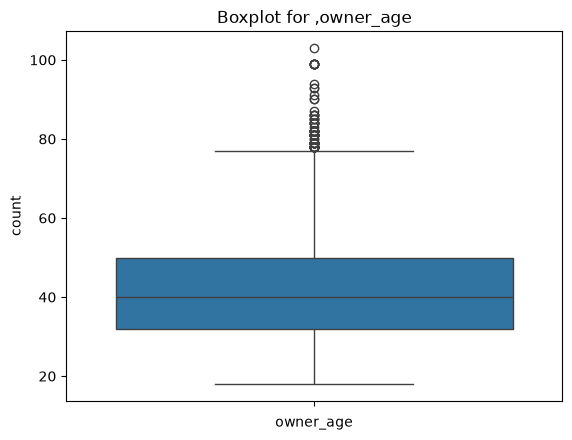

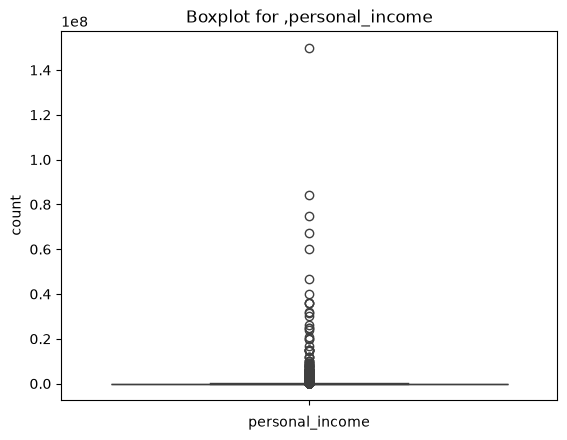

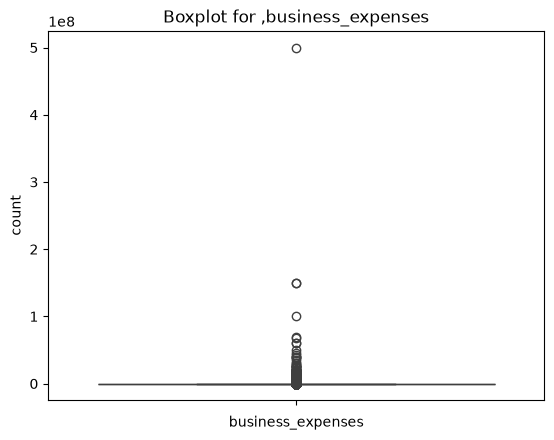

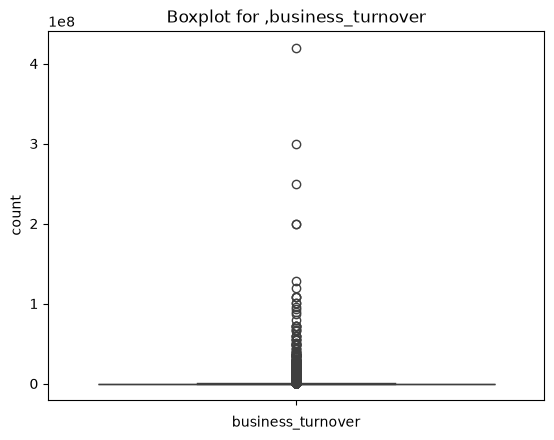

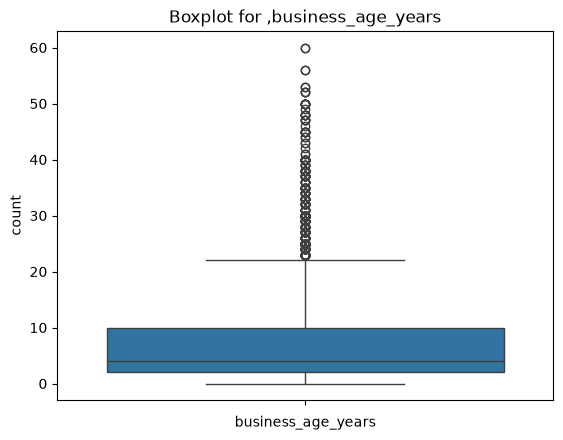

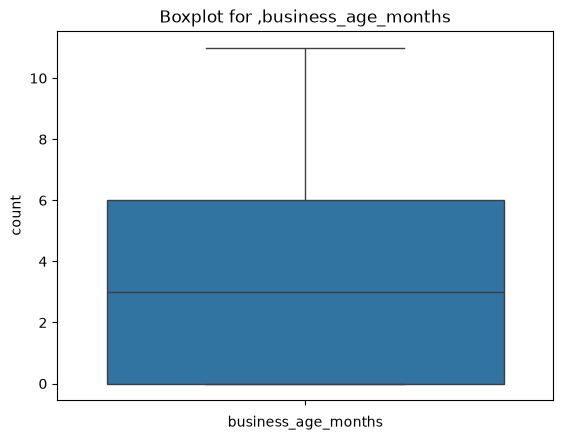

In [247]:
num_cols = financial_health.select_dtypes(include=['int','float']).columns.to_list()

print(num_cols)

for col in num_cols:
    plt.Figure(figsize=(7,4))
    sns.boxplot(data = financial_health , y = col)
    plt.title(f"Boxplot for ,{col}")
    plt.xlabel(col)
    plt.ylabel('count')
    plt.show()

#### Cleaning Categorical Columns

In [248]:
financial_health[categorical_columns] = financial_health[categorical_columns].apply(
    lambda x: x.str.strip()
)

In [249]:
mapping = {"Used to have but don't have now" : "Previously had but don't have now", 
            "Used to have but don’t have now" : "Previously had but don't have now"
           }
financial_health = financial_health.replace(mapping)

#### Percentage of NaN in CURRENT_PROBLEM_CASH_FLOW

In [250]:
(financial_health['current_problem_cash_flow'].value_counts()/len(financial_health)) * 100

current_problem_cash_flow
Yes    27.947598
No     19.619464
0      13.152423
Name: count, dtype: float64

In [251]:
financial_health.shape

(9618, 39)

#### Replace '0' with N/A

In [252]:
financial_health['current_problem_cash_flow'] = (
    financial_health['current_problem_cash_flow'].replace('0', 'N/A')
)

In [253]:
financial_health['current_problem_cash_flow'].unique()

<StringArray>
['Yes', nan, 'No', 'N/A']
Length: 4, dtype: str

#### Replacing null values with Unknown

In [254]:
# financial_health = financial_health.fillna('Unknown')

In [255]:
basic_checks(financial_health)

----------------------------------- Duplicates -----------------------------------
0
----------------------------------- Shape -----------------------------------
(9618, 39)
----------------------------------- Missing Values -----------------------------------
ID                                                                     0
country                                                                0
owner_age                                                              0
attitude_stable_business_environment                                   2
attitude_worried_shutdown                                              2
compliance_income_tax                                                  4
perception_insurance_doesnt_cover_losses                               5
perception_cannot_afford_insurance                                     5
personal_income                                                      109
business_expenses                                                    229
business_

,count,mean,std,min,25%,50%,75%,max
owner_age,9618.0,4.170534e+01,1.331401e+01,18.0,32.0,40.0,50.0,103.0
personal_income,9509.0,2.627345e+05,2.566268e+06,0.0,300.0,2000.0,25000.0,150000000.0
business_expenses,9389.0,4.583838e+05,6.184746e+06,0.0,700.0,3000.0,25000.0,500000000.0
business_turnover,9402.0,1.348210e+06,8.804741e+06,0.0,1500.0,6000.0,50000.0,420000000.0
business_age_years,9366.0,7.030536e+00,7.650349e+00,0.0,2.0,4.0,10.0,60.0
business_age_months,5507.0,3.636281e+00,3.386488e+00,0.0,0.0,3.0,6.0,11.0


None
----------------------------------- Summary Statistics Categorical Data -----------------------------------


,count,unique,top,freq
ID,9618,9618,ID_3CFL0U,1
country,9618,4,eswatini,2674
attitude_stable_business_environment,9616,3,Yes,5820
attitude_worried_shutdown,9616,3,No,5804
compliance_income_tax,9614,4,No,8010
perception_insurance_doesnt_cover_losses,9613,3,No,4486
perception_cannot_afford_insurance,9613,3,Yes,6056
motor_vehicle_insurance,7374,4,Never had,6994
has_mobile_money,6867,4,Have now,4876
current_problem_cash_flow,5840,3,Yes,2688


None


#### Check number of nulls

In [256]:
# Percentage of null values per column
(financial_health.isnull().sum()/len(financial_health))*100

ID                                                                   0.000000
country                                                              0.000000
owner_age                                                            0.000000
attitude_stable_business_environment                                 0.020794
attitude_worried_shutdown                                            0.020794
compliance_income_tax                                                0.041589
perception_insurance_doesnt_cover_losses                             0.051986
perception_cannot_afford_insurance                                   0.051986
personal_income                                                      1.133292
business_expenses                                                    2.380952
business_turnover                                                    2.245789
business_age_years                                                   2.620087
motor_vehicle_insurance                                         

In [257]:
financial_health.columns

Index(['ID', 'country', 'owner_age', 'attitude_stable_business_environment',
       'attitude_worried_shutdown', 'compliance_income_tax',
       'perception_insurance_doesnt_cover_losses',
       'perception_cannot_afford_insurance', 'personal_income',
       'business_expenses', 'business_turnover', 'business_age_years',
       'motor_vehicle_insurance', 'has_mobile_money',
       'current_problem_cash_flow', 'has_cellphone', 'owner_sex',
       'offers_credit_to_customers', 'attitude_satisfied_with_achievement',
       'has_credit_card', 'keeps_financial_records',
       'perception_insurance_companies_dont_insure_businesses_like_yours',
       'perception_insurance_important', 'has_insurance',
       'covid_essential_service', 'attitude_more_successful_next_year',
       'problem_sourcing_money', 'marketing_word_of_mouth', 'has_loan_account',
       'has_internet_banking', 'has_debit_card', 'future_risk_theft_stock',
       'business_age_months', 'medical_insurance', 'funeral_insura

##### Replacing Nulls in Categorical cols with Unknown and mode where applicable

In [258]:
categorical_columns = financial_health.select_dtypes(include=['str','object']).columns.to_list()
categorical_columns

['ID',
 'country',
 'attitude_stable_business_environment',
 'attitude_worried_shutdown',
 'compliance_income_tax',
 'perception_insurance_doesnt_cover_losses',
 'perception_cannot_afford_insurance',
 'motor_vehicle_insurance',
 'has_mobile_money',
 'current_problem_cash_flow',
 'has_cellphone',
 'owner_sex',
 'offers_credit_to_customers',
 'attitude_satisfied_with_achievement',
 'has_credit_card',
 'keeps_financial_records',
 'perception_insurance_companies_dont_insure_businesses_like_yours',
 'perception_insurance_important',
 'has_insurance',
 'covid_essential_service',
 'attitude_more_successful_next_year',
 'problem_sourcing_money',
 'marketing_word_of_mouth',
 'has_loan_account',
 'has_internet_banking',
 'has_debit_card',
 'future_risk_theft_stock',
 'medical_insurance',
 'funeral_insurance',
 'motivation_make_more_money',
 'uses_friends_family_savings',
 'uses_informal_lender',
 'Target']

In [259]:
financial_health[categorical_columns] = financial_health[categorical_columns].fillna("Unknown")

In [260]:
financial_health[categorical_columns].isnull().sum()

ID                                                                  0
country                                                             0
attitude_stable_business_environment                                0
attitude_worried_shutdown                                           0
compliance_income_tax                                               0
perception_insurance_doesnt_cover_losses                            0
perception_cannot_afford_insurance                                  0
motor_vehicle_insurance                                             0
has_mobile_money                                                    0
current_problem_cash_flow                                           0
has_cellphone                                                       0
owner_sex                                                           0
offers_credit_to_customers                                          0
attitude_satisfied_with_achievement                                 0
has_credit_card     

### Cleaning Numerical Columns

In [261]:
numerical_cols = financial_health.select_dtypes(
    include=['int64', 'float64']
).columns

financial_health[numerical_cols].isnull().sum()

owner_age                 0
personal_income         109
business_expenses       229
business_turnover       216
business_age_years      252
business_age_months    4111
dtype: int64

In [262]:
financial_health[numerical_cols].describe()

,owner_age,personal_income,business_expenses,business_turnover,business_age_years,business_age_months
count,9618.000000,9.509000e+03,9.389000e+03,9.402000e+03,9366.000000,5507.000000
mean,41.705344,2.627345e+05,4.583838e+05,1.348210e+06,7.030536,3.636281
std,13.314010,2.566268e+06,6.184746e+06,8.804741e+06,7.650349,3.386488
min,18.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000
25%,32.000000,3.000000e+02,7.000000e+02,1.500000e+03,2.000000,0.000000
50%,40.000000,2.000000e+03,3.000000e+03,6.000000e+03,4.000000,3.000000
75%,50.000000,2.500000e+04,2.500000e+04,5.000000e+04,10.000000,6.000000
max,103.000000,1.500000e+08,5.000000e+08,4.200000e+08,60.000000,11.000000


In [263]:
(financial_health[numerical_cols].isnull().sum()/len(financial_health[numerical_cols]))*100

owner_age               0.000000
personal_income         1.133292
business_expenses       2.380952
business_turnover       2.245789
business_age_years      2.620087
business_age_months    42.742774
dtype: float64

In [264]:
# Drop the column that has more than 40% Null Values
financial_health.drop(columns=['business_age_months'], inplace=True)

In [265]:
# Update cols
numerical_columns = financial_health.select_dtypes(include='number').columns.tolist()

In [266]:
# Drop nulls that's below 5%
financial_health.dropna(subset=numerical_columns, inplace=True)

### Visualization

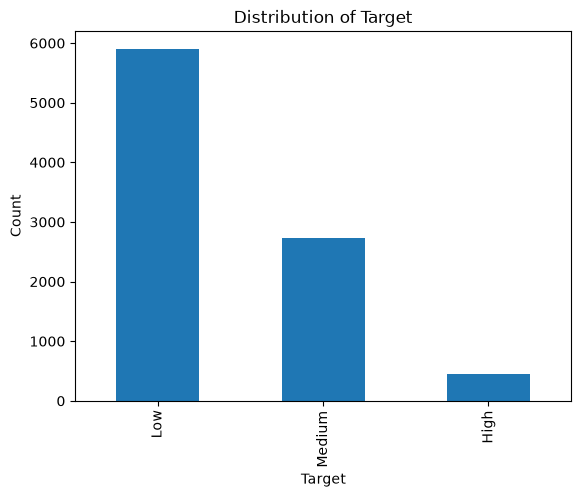

In [267]:
financial_health['Target'].value_counts().plot(kind='bar')

plt.title('Distribution of Target')
plt.xlabel('Target')
plt.ylabel('Count')
plt.show()

#### Hypothesis test


#### Categorical Columns

In [268]:
categorical_columns.remove('Target')

In [269]:
for column in categorical_columns: 
    print('-'*40, column.upper(),'-'*40)
    h0 = f'There is no association between {column} and target"'
    h1 = f'There is an association between {column} and target"'

    contingency_table = pd.crosstab(financial_health[column], financial_health['Target'])
    chi2_stats,p_value , dof , expected = chi2_contingency(contingency_table)

    if p_value <= 0.05:
        print('Reject the null hypothesis')

    else:
        print('Fail to reject the null hypothesis')

---------------------------------------- ID ----------------------------------------
Fail to reject the null hypothesis
---------------------------------------- COUNTRY ----------------------------------------
Reject the null hypothesis
---------------------------------------- ATTITUDE_STABLE_BUSINESS_ENVIRONMENT ----------------------------------------
Reject the null hypothesis
---------------------------------------- ATTITUDE_WORRIED_SHUTDOWN ----------------------------------------
Reject the null hypothesis
---------------------------------------- COMPLIANCE_INCOME_TAX ----------------------------------------
Reject the null hypothesis
---------------------------------------- PERCEPTION_INSURANCE_DOESNT_COVER_LOSSES ----------------------------------------
Reject the null hypothesis
---------------------------------------- PERCEPTION_CANNOT_AFFORD_INSURANCE ----------------------------------------
Reject the null hypothesis
---------------------------------------- MOTOR_VEHICLE_IN

numerical cols

In [270]:
for column in numerical_columns:
    print('-' * 40, column.upper(), '-' * 40)

    H0 = f"There is no difference in the distribution of {column} across target"
    H1 = f"There is at least one difference in the distribution of {column} across target"

    groups = [group[column].values for name, group in financial_health.groupby('Target')]

    stat, p_value = kruskal(*groups)

    if p_value <= 0.05:
        print("Reject the null hypothesis")
    else:
        print("Fail to reject the null hypothesis")

    print("p-value:", p_value)

---------------------------------------- OWNER_AGE ----------------------------------------
Reject the null hypothesis
p-value: 4.592937888937074e-22
---------------------------------------- PERSONAL_INCOME ----------------------------------------
Reject the null hypothesis
p-value: 1.87160256392751e-25
---------------------------------------- BUSINESS_EXPENSES ----------------------------------------
Reject the null hypothesis
p-value: 8.685418057994929e-39
---------------------------------------- BUSINESS_TURNOVER ----------------------------------------
Reject the null hypothesis
p-value: 2.681238425351856e-46
---------------------------------------- BUSINESS_AGE_YEARS ----------------------------------------
Reject the null hypothesis
p-value: 6.722667319324768e-05


Test Split 

In [271]:
X = financial_health.drop(columns=['Target','ID'])
y = financial_health['Target']

In [272]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [273]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (7275, 36)
X_test: (1819, 36)
y_train: (7275,)
y_test: (1819,)


Identify numerical and categorical features 


In [274]:
categorical_features = X_train.select_dtypes(
    include=['object', 'str', 'category']
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=['number']
).columns.tolist()

In [275]:
print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['country', 'attitude_stable_business_environment', 'attitude_worried_shutdown', 'compliance_income_tax', 'perception_insurance_doesnt_cover_losses', 'perception_cannot_afford_insurance', 'motor_vehicle_insurance', 'has_mobile_money', 'current_problem_cash_flow', 'has_cellphone', 'owner_sex', 'offers_credit_to_customers', 'attitude_satisfied_with_achievement', 'has_credit_card', 'keeps_financial_records', 'perception_insurance_companies_dont_insure_businesses_like_yours', 'perception_insurance_important', 'has_insurance', 'covid_essential_service', 'attitude_more_successful_next_year', 'problem_sourcing_money', 'marketing_word_of_mouth', 'has_loan_account', 'has_internet_banking', 'has_debit_card', 'future_risk_theft_stock', 'medical_insurance', 'funeral_insurance', 'motivation_make_more_money', 'uses_friends_family_savings', 'uses_informal_lender']

Numerical features:
['owner_age', 'personal_income', 'business_expenses', 'business_turnover', 'business_age_years'

Standadize the Columns 

In [276]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

## Modelling

In [277]:

model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

Train the model


In [278]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['High','Low','Medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](36,)","['country','owner_age','attitude_stable_business_environment',..., 'motivation_make_more_money','uses_friends_family_savings', 'uses_informal_lender']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,36
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the no

Make Prediction

In [279]:
y_pred = model.predict(X_test)

Evaluate the model

In [ ]:

accuracy = accuracy_score(y_test, y_pred)
print(accuracy)

0.8691588785046729


In [281]:
print('classification report for logistic regression')
print(classification_report(y_pred, y_test))

classification report for logistic regression
              precision    recall  f1-score   support

        High       0.60      0.71      0.65        78
         Low       0.98      0.88      0.93      1305
      Medium       0.68      0.86      0.76       436

    accuracy                           0.87      1819
   macro avg       0.75      0.82      0.78      1819
weighted avg       0.89      0.87      0.88      1819



Prediction using KNN

In [282]:
print(X_train.columns.tolist())

['country', 'owner_age', 'attitude_stable_business_environment', 'attitude_worried_shutdown', 'compliance_income_tax', 'perception_insurance_doesnt_cover_losses', 'perception_cannot_afford_insurance', 'personal_income', 'business_expenses', 'business_turnover', 'business_age_years', 'motor_vehicle_insurance', 'has_mobile_money', 'current_problem_cash_flow', 'has_cellphone', 'owner_sex', 'offers_credit_to_customers', 'attitude_satisfied_with_achievement', 'has_credit_card', 'keeps_financial_records', 'perception_insurance_companies_dont_insure_businesses_like_yours', 'perception_insurance_important', 'has_insurance', 'covid_essential_service', 'attitude_more_successful_next_year', 'problem_sourcing_money', 'marketing_word_of_mouth', 'has_loan_account', 'has_internet_banking', 'has_debit_card', 'future_risk_theft_stock', 'medical_insurance', 'funeral_insurance', 'motivation_make_more_money', 'uses_friends_family_savings', 'uses_informal_lender']


In [283]:
categorical_features = X_train.select_dtypes(
    include=['object', 'str', 'category']
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=['number']
).columns.tolist()

In [284]:
knn_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=5, metric='minkowski'))
])

In [285]:
knn_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['High','Low','Medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](36,)","['country','owner_age','attitude_stable_business_environment',..., 'motivation_make_more_money','uses_friends_family_savings', 'uses_informal_lender']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,36
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the no

In [287]:

knn_model.fit(X_train, y_train)

knn_pred = knn_model.predict(X_test)

In [293]:
knn_accuracy = accuracy_score(y_test, knn_pred)
print(accuracy)

0.8691588785046729


In [292]:
print('Classification report for KNN')
print(classification_report(y_test, knn_pred))

Classification report for KNN
              precision    recall  f1-score   support

        High       0.64      0.35      0.45        91
         Low       0.80      0.94      0.86      1181
      Medium       0.72      0.50      0.59       547

    accuracy                           0.78      1819
   macro avg       0.72      0.60      0.64      1819
weighted avg       0.77      0.78      0.76      1819

